In [22]:
import numpy as np
import pandas as pd
from scipy.integrate import cumulative_trapezoid
import matplotlib.pyplot as plt
import os
from matplotlib.ticker import AutoMinorLocator
from matplotlib.ticker import MultipleLocator

In [2]:
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.linewidth": 1.4,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 10
})

In [3]:
T                 = 298.0   

DT_PS             = 0.004
N_BLOCKS_PER_RUN  = 16
ACF_MAX_LAG_PS    = 500.0
PLATEAU_START_PS  = 100.0
PLATEAU_END_PS    = 500.0

KB     = 1.380649e-23
BAR2PA = 1.0e5
NM3_M3 = 1.0e-27

In [4]:
RUN_NAMES = ['run1', 'run2', 'run3', 'run4', 'run5']

# def read_xvg(filename):
#     with open(filename) as f:
#         n_skip = sum(1 for line in f if line.lstrip().startswith(('#', '@')))
#     return pd.read_csv(
#         filename, sep=r'\s+', skiprows=n_skip,
#         header=None, dtype=float, engine='python',
#     )

In [5]:
_xvg_cache = {}  # filename -> DataFrame, so each file is parsed from disk only once

def read_xvg(filename):
    if filename in _xvg_cache:
        return _xvg_cache[filename]

    with open(filename) as f:
        n_skip = sum(1 for line in f if line.lstrip().startswith(('#', '@')))
    df = pd.read_csv(
        filename,
        sep=r'\s+',
        skiprows=n_skip,
        header=None,
        dtype=float,
        engine='python',
    )
    _xvg_cache[filename] = df
    return df

def clear_xvg_cache():
    """Call this if you edit the .xvg files on disk and need a fresh reload."""
    _xvg_cache.clear()
    

In [6]:
def get_volume(volume_files):
    vols = [read_xvg(f).iloc[:, 1].mean() for f in volume_files]
    return float(np.mean(vols))

In [7]:
def extract_stress_components(df):
    t = df.iloc[:, 0].to_numpy()
    Pxy = df.iloc[:, 2].to_numpy()
    Pxz = df.iloc[:, 3].to_numpy()
    Pyz = df.iloc[:, 5].to_numpy()
    return t, np.array([Pxy, Pxz, Pyz])

In [8]:
def compute_acf_fft(x):
    # x    = x - x.mean()
    n    = len(x)
    nfft = 1 << (2 * n - 1).bit_length()
    F    = np.fft.rfft(x, n=nfft)
    acf  = np.fft.irfft(F * F.conj())[:n].real
    acf /= np.arange(n, 0, -1)
    return acf

def running_integral(acf_Pa2, dt_s, V_m3, kT):
    return (V_m3 / kT) * cumulative_trapezoid(acf_Pa2, dx=dt_s, initial=0.0)

In [9]:
def process_system(directory, label):
    input_files  = [os.path.join(directory, f'{r}_pressure.xvg') for r in RUN_NAMES]
    volume_files = [os.path.join(directory, f'{r}_volume.xvg') for r in RUN_NAMES]

    V_nm3 = get_volume(volume_files)
    V_m3  = V_nm3 * NM3_M3
    kT    = KB * T
    dt_s  = DT_PS * 1e-12

    print(f'[{label}] Volume : {V_nm3:.4f} nm³')
    print(f'[{label}] kT     : {kT:.4e} J')
    print(f'[{label}] dt     : {dt_s:.4e} s')

    records = []
    max_lag_frames = int(ACF_MAX_LAG_PS / DT_PS)

    for run_idx, fname in enumerate(input_files):
        print(f'[{label}] Run {run_idx + 1}: {fname}')
        data = read_xvg(fname)
        t_full, comps = extract_stress_components(data)
        n_total = len(data)
        block_size = n_total // N_BLOCKS_PER_RUN
        max_lag  = min(max_lag_frames, block_size // 5)
        t_lag_ps = np.arange(max_lag) * DT_PS

        for blk in range(N_BLOCKS_PER_RUN):
            s, e = blk * block_size, (blk + 1) * block_size
            etas = []
            for ci in range(3):
                acf_bar2 = compute_acf_fft(comps[ci, s:e])[:max_lag]
                acf_Pa2  = acf_bar2 * BAR2PA**2
                eta      = running_integral(acf_Pa2, dt_s, V_m3, kT)
                etas.append(eta)
            eta_avg  = np.mean(etas, axis=0)
            mask     = (t_lag_ps >= PLATEAU_START_PS) & (t_lag_ps <= PLATEAU_END_PS)
            eta_plat = np.mean(eta_avg[mask]) * 1e3

            records.append({
                'label'    : f'R{run_idx+1}_B{blk+1}',
                'run'      : run_idx + 1,
                'block'    : blk + 1,
                'eta_mPas' : eta_plat,
                'eta_Pa_s' : eta_avg,
                't_ps'     : t_lag_ps,
            })
            print(f'  [{label}] {f"R{run_idx+1}_B{blk+1}"}: η = {eta_plat:.4f} mPa·s')

    df = pd.DataFrame([{k: v for k, v in r.items() if not isinstance(v, np.ndarray)} for r in records])

    min_len  = min(len(r['eta_Pa_s']) for r in records)
    t_ps     = records[0]['t_ps'][:min_len]
    eta_mat  = np.vstack([r['eta_Pa_s'][:min_len] for r in records]) * 1e3   # mPa·s -> using cP equivalently
    eta_mean = eta_mat.mean(axis=0)
    eta_std  = eta_mat.std(axis=0, ddof=1)
    eta_se   = eta_std / np.sqrt(len(records))

    print(f'[{label}] η (mean integral at t_end): {eta_mean[-1]:.4f} mPa·s')

    return {
        'label'   : label,
        't_ps'    : t_ps,
        'eta_mat' : eta_mat,
        'eta_mean': eta_mean,
        'eta_std' : eta_std,
        'eta_se'  : eta_se,
        'df'      : df,
    }

In [10]:
DMC = process_system('1-DMC', 'DMC')
DEC = process_system('2-DEC', 'DEC')

[DMC] Volume : 455.9492 nm³
[DMC] kT     : 4.1143e-21 J
[DMC] dt     : 4.0000e-15 s
[DMC] Run 1: 1-DMC/run1_pressure.xvg
  [DMC] R1_B1: η = 0.9203 mPa·s
  [DMC] R1_B2: η = 0.4644 mPa·s
  [DMC] R1_B3: η = 0.5548 mPa·s
  [DMC] R1_B4: η = 0.6732 mPa·s
  [DMC] R1_B5: η = 0.5566 mPa·s
  [DMC] R1_B6: η = 0.5298 mPa·s
  [DMC] R1_B7: η = 0.6595 mPa·s
  [DMC] R1_B8: η = 0.4125 mPa·s
  [DMC] R1_B9: η = 0.4871 mPa·s
  [DMC] R1_B10: η = 0.5555 mPa·s
  [DMC] R1_B11: η = 0.5717 mPa·s
  [DMC] R1_B12: η = 0.6311 mPa·s
  [DMC] R1_B13: η = 0.3324 mPa·s
  [DMC] R1_B14: η = 0.5803 mPa·s
  [DMC] R1_B15: η = 0.7370 mPa·s
  [DMC] R1_B16: η = 0.6525 mPa·s
[DMC] Run 2: 1-DMC/run2_pressure.xvg
  [DMC] R2_B1: η = 0.5882 mPa·s
  [DMC] R2_B2: η = 0.7265 mPa·s
  [DMC] R2_B3: η = 0.5891 mPa·s
  [DMC] R2_B4: η = 0.7471 mPa·s
  [DMC] R2_B5: η = 0.5195 mPa·s
  [DMC] R2_B6: η = 0.7686 mPa·s
  [DMC] R2_B7: η = 0.6672 mPa·s
  [DMC] R2_B8: η = 0.5519 mPa·s
  [DMC] R2_B9: η = 0.5434 mPa·s
  [DMC] R2_B10: η = 0.8690 mPa·s
  

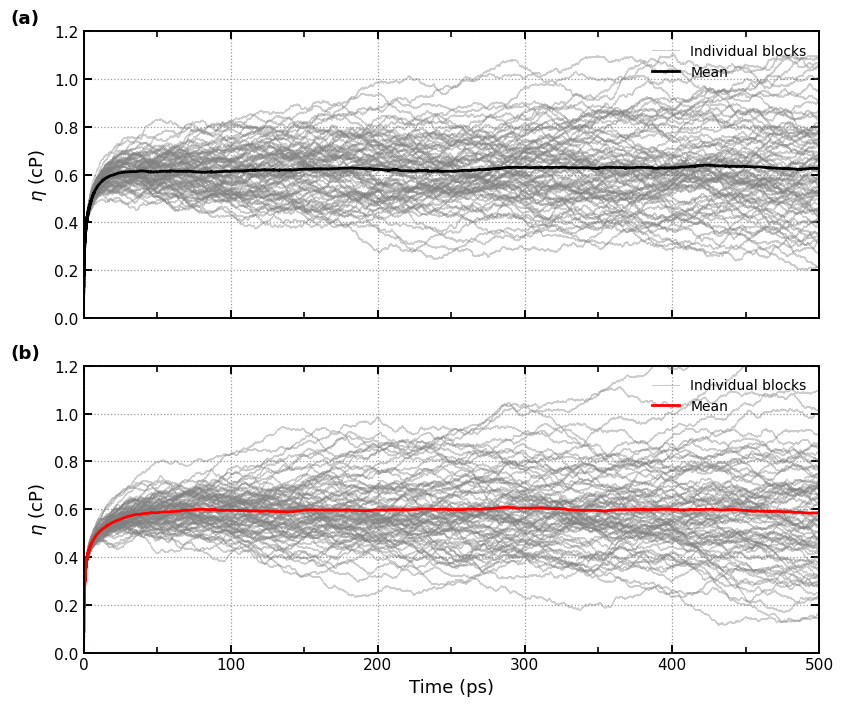

In [33]:
def style_axis(ax):
    ax.grid(True, which='major', axis='both', linestyle=':', linewidth=0.9, color='0.6')
    ax.tick_params(direction='in', length=6, width=1.4, top=True, right=True)
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.tick_params(which='minor', direction='in', length=4, width=1.2, top=True, right=True)

panel_labels = ['(a)', '(b)']

fig1, axes1 = plt.subplots(2, 1, figsize=(8.4, 7.2), sharex=True)
for ax, sysdata, color, panel in zip(axes1, [DMC, DEC], ['black', 'red'], panel_labels):
    t_ps     = sysdata['t_ps']
    eta_mat  = sysdata['eta_mat']
    eta_mean = sysdata['eta_mean']
    for i, eta_blk in enumerate(eta_mat):
        ax.plot(t_ps, eta_blk, color='grey', alpha=0.4, linewidth=0.8,
                 label='Individual blocks' if i == 0 else None)
    ax.plot(t_ps, eta_mean, color=color, linewidth=2.0, label='Mean')
    # ax.set_xlabel('Time (ps)')
    ax.set_ylabel(r'$\eta$ (cP)')
    ax.set_title(panel, x=-0.1, loc='left', fontweight='bold')
    style_axis(ax)
    ax.set_xlim(0, 500)
    ax.set_ylim(0, 1.2)


    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.4)
        
    ax.legend(frameon=False, loc='upper right')
axes1[-1].set_xlabel('Time (ps)')
plt.tight_layout()
plt.savefig('running_integrals_DMC_DEC.png', dpi=600, bbox_inches='tight')
plt.show()

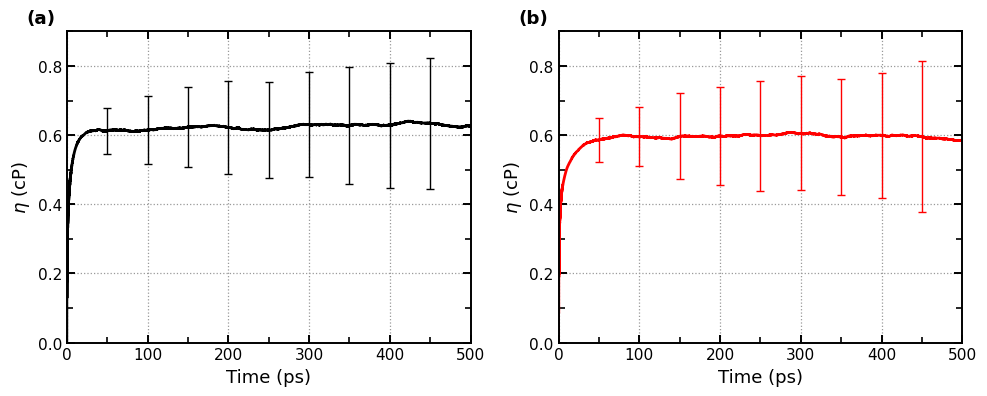

In [31]:
panel_labels = ['(a)', '(b)']

fig2, axes2 = plt.subplots(1, 2, figsize=(10, 4.1), sharex=True)
# fig2, axes2 = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, sysdata, color, panel in zip(axes2, [DMC, DEC], ['black', 'red'], panel_labels):
    t_ps     = sysdata['t_ps']
    eta_mean = sysdata['eta_mean']
    eta_std  = sysdata['eta_std']
    ax.plot(t_ps, eta_mean, color=color, linewidth=2.0, label=r'Mean $\eta$')
    step = max(1, len(t_ps) // 10)
    ax.errorbar(t_ps[::step], eta_mean[::step], yerr=eta_std[::step],
                fmt='none', color=color, capsize=3, linewidth=1.0)
    ax.set_xlabel('Time (ps)')
    ax.set_ylabel(r'$\eta$ (cP)')
    ax.set_title(panel , x=-0.1, loc='left', fontweight='bold')
    style_axis(ax)
    ax.set_xlim(0, 500)
    ax.set_ylim(0, 0.9)
    # ax.tick_params()
    ax.yaxis.set_major_locator(MultipleLocator(0.2))
    ax.yaxis.set_minor_locator(MultipleLocator(0.1))
    ax.grid(True, which='major', axis='y', linestyle=':', linewidth=0.9, color='0.6')


    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.4)

    # ax.legend(frameon=False, loc='lower right')

# axes2[0].set_ylabel(r'$\eta$ (cP)')
plt.tight_layout()
plt.savefig('error_bands_DMC_DEC.png', dpi=600, bbox_inches='tight')
plt.show()

In [32]:
def block_average(t_ps, eta_mean, start=100, end=500, block=100):
    vals = [
        eta_mean[(t_ps >= s) & (t_ps < s + block)].mean()
        for s in np.arange(start, end, block)
    ]
    vals = np.array(vals)
    return vals.mean(), vals.std(ddof=1), vals


DMC_mean, DMC_std, DMC_blocks = block_average(
    DMC['t_ps'], DMC['eta_mean']
)

DEC_mean, DEC_std, DEC_blocks = block_average(
    DEC['t_ps'], DEC['eta_mean']
)

print(f'DMC: η = {DMC_mean:.4f} ± {DMC_std:.4f} mPa·s')
print(f'DEC: η = {DEC_mean:.4f} ± {DEC_std:.4f} mPa·s')

print('DMC blocks:', DMC_blocks)
print('DEC blocks:', DEC_blocks)

DMC: η = 0.6257 ± 0.0055 mPa·s
DEC: η = 0.5969 ± 0.0035 mPa·s
DMC blocks: [0.62197656 0.62018116 0.62936853 0.63145033]
DEC blocks: [0.5942503  0.60077218 0.59896573 0.59354486]
